# Early Time-Series Crop Classification in the Nile Delta
## Data Preprocessing and Feature Engineering

The EDA notebook cleaned the dataset and kept 978,660 samples. This notebook prepares those samples for the models: it handles the cloud gaps, encodes the classes, builds the features and saves every decision, so that all the models are trained on exactly the same input.

The feature code lives in `features.py`. The model notebooks and, later, the platform use the same file, so a field is described in the same way in training and in use.

| Part | Topic |
|---|---|
| 1 | Data Preprocessing |
| 2 | Feature Engineering |
| 3 | Save the Outputs |
| 4 | Summary |

---
# Library

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import features

---
# 1. Data Preprocessing

## Read Data
The models read the raw 10-day (dekad) arrays, not the CSV tables used in the EDA. The arrays keep the ten satellite bands and leave the cloud gaps empty; in the CSV tables the gaps were already filled with values from later dates, which an early prediction cannot know.

A model is trained for each season, because winter and summer have different crops and a different number of dekads. Only the clean samples of the EDA are read.

In [2]:
data = {season: features.load(season) for season in features.SEASONS}

for season, (X, meta) in data.items():
    print(f"{season}: {X.shape[0]:,} samples, {X.shape[1]} dekads, {X.shape[2]} bands")
print("Total samples:", sum(len(meta) for _, meta in data.values()))

winter: 459,501 samples, 24 dekads, 10 bands
summer: 519,159 samples, 18 dekads, 10 bands
Total samples: 978660


Each season is a 3-D array: samples × dekads × bands. Winter has 24 dekads (1 October to 31 May) and summer 18 (1 May to 31 October). The bands are surface reflectance, from 0 to 1.

In [3]:
samples = pd.concat([meta for _, meta in data.values()], ignore_index=True)
samples.sample(5, random_state=42)

,sample_id,pixel_id,region,season,season_key,crop,split,fold,block_id
109189,116942,135420718,ZAN,winter,W2324,clover,test,0,ZAN_343
448386,946933,225160772,SGZ,winter,W2324,water,test,0,SGZ_135
68557,73282,126861981,ZAN,winter,W2324,clover,test,0,ZAN_269
839679,645962,228700215,SGZ,summer,S2023,built_up,train,3,SGZ_155
665929,467735,131070701,ZAN,summer,S2024,orchards,train,2,ZAN_303


## Check Splits

The split into train, validation and test was made in whole 2 km blocks when the dataset was built. It is used as it is; the check below makes sure that no block and no pixel is found in two splits.

In [4]:
pd.crosstab(samples["season"], samples["split"], margins=True)

split,test,train,val,All
season,,,,
summer,105833,309361,103965,519159
winter,89978,278799,90724,459501
All,195811,588160,194689,978660


In [5]:
split_code = samples["split"].astype("category").cat.codes
print("Blocks in more than one split:", (split_code.groupby(samples["block_id"]).nunique() > 1).sum())
print("Pixels in more than one split:", (split_code.groupby(samples["pixel_id"]).nunique() > 1).sum())

Blocks in more than one split: 0


Pixels in more than one split: 0


No block and no pixel is found in two splits, so what a model learns from a field cannot reach the validation or test samples of the same place. In both seasons about 60% of the samples are for training, 20% for validation and 20% for test. The splits are used as they are.

## Check Null (Missing Values)
A dekad is missing when every satellite pass in it was cloudy. The EDA found no nulls because its CSV tables were already filled; the raw arrays keep the gaps. A missing dekad has all ten bands missing, so the first band is enough to count them.

In [6]:
for season, (X, meta) in data.items():
    missing = np.isnan(X[:, :, 0])
    print(f"{season}: missing dekads {missing.mean() * 100:.1f}%, samples with no clear dekad: {missing.all(axis=1).sum()}")

winter: missing dekads 21.7%, samples with no clear dekad: 0
summer: missing dekads 8.7%, samples with no clear dekad: 0


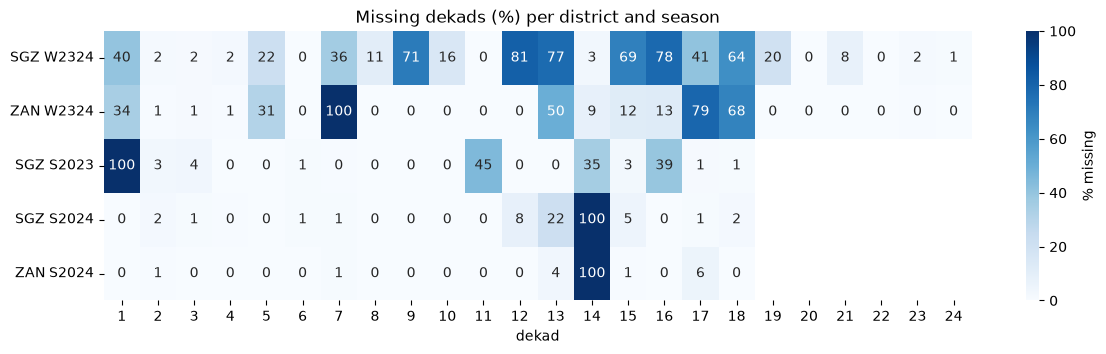

In [7]:
rows = []
for season, (X, meta) in data.items():
    missing = pd.DataFrame(np.isnan(X[:, :, 0]), columns=range(1, X.shape[1] + 1))
    missing["set"] = (meta["region"] + " " + meta["season_key"]).to_numpy()
    rows.append(missing.groupby("set").mean() * 100)

plt.figure(figsize=(14, 3.5))
sns.heatmap(pd.concat(rows), annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% missing"})
plt.title("Missing dekads (%) per district and season")
plt.xlabel("dekad")
plt.ylabel("")
plt.show()

21.7% of the winter dekads and 8.7% of the summer dekads are missing, and no sample is missing completely, so no sample is dropped.

- Four dekads have no clear image at all: dekad 7 of Zankalon winter, dekad 1 of Sidi Ghazi summer 2023, and dekad 14 of both 2024 summers (the archive has no images from 9 to 24 September 2024).
- The cloudiest set is Sidi Ghazi winter: 69% to 81% of its samples are missing in dekads 9, 12, 13, 15 and 16.

Dropping rows is not possible, since almost every sample has gaps, and the mean or median of a column would ignore the time of year. The gaps are therefore filled in time, as the next step explains.

## Fill Missing Values Without Using the Future
The goal is to recognise a crop early, from the first k dekads of the season only. Filling a gap by interpolation over the whole season uses the dekads after k, which do not exist yet at that date: the model would be tested with information from the future.

The rule is therefore: **cut first, then fill**. `features.truncate` keeps the first k dekads, and `features.fill` fills the gaps between clear dekads linearly; after the last clear dekad the last clear value is kept. The check takes 50,000 winter samples and compares the two ways of filling the first k dekads.

In [8]:
X, meta = data["winter"]
rng = np.random.default_rng(42)
part = X[rng.choice(len(X), 50_000, replace=False)]
whole = features.fill(part)

for k in [3, 6, 9, 12, 18]:
    cut = features.fill(features.truncate(part, k))
    gaps = np.isnan(part[:, :k, 0])
    changed = ~np.isclose(whole[:, :k, 0], cut[:, :k, 0])
    print(f"first {k:2d} dekads: {gaps.mean() * 100:4.1f}% are gaps, {changed[gaps].mean() * 100:4.1f}% of the gaps get a value from later dekads")

first  3 dekads: 13.2% are gaps,  4.0% of the gaps get a value from later dekads


first  6 dekads: 11.2% are gaps,  0.0% of the gaps get a value from later dekads


first  9 dekads: 19.5% are gaps, 23.6% of the gaps get a value from later dekads


first 12 dekads: 18.6% are gaps, 17.8% of the gaps get a value from later dekads


first 18 dekads: 28.0% are gaps, 25.4% of the gaps get a value from later dekads


When the season is cut after 9 dekads or more, 18% to 25% of the gaps would be filled with information from later dekads if the whole season were interpolated. After 6 dekads the two ways agree, because those dekads have few inner gaps.

The decision:
- **LightGBM** receives the cut series with its gaps, because it handles missing values itself.
- **Random Forest, MiniRocket and LSTM** receive `features.fill(features.truncate(C, k))`.
- Nothing is filled in the stored data; filling happens when a model reads it.

## Check Outliers
The outliers of the five indices were checked in the EDA. The bands are new here. Surface reflectance is physically between 0 and 1, so values outside this range are the first thing to check.

In [9]:
for season, (X, meta) in data.items():
    clear = X[np.isfinite(X)]
    print(f"{season}: min {clear.min():.3f}, max {clear.max():.3f}, "
          f"values above 1: {(clear > 1).sum():,} of {len(clear):,} ({(clear > 1).mean() * 100:.4f}%)")

winter: min 0.000, max 1.528, values above 1: 22 of 86,327,740 (0.0000%)


summer: min 0.000, max 1.539, values above 1: 28 of 85,334,520 (0.0000%)


Only 22 winter and 28 summer values are above 1, out of more than 85 million in each season (the highest is 1.54), and none is below 0. They are far too few to affect any model.

**Treatment: Ignoring.**

## Encode Target
The models need the class as a number. Each season gets a fixed list of its classes in alphabetical order; the position in the list is the class number. The list is saved, so the platform turns a predicted number back into the same crop name.

In [10]:
classes = {season: sorted(meta["crop"].unique()) for season, (X, meta) in data.items()}
for season, (X, meta) in data.items():
    meta["y"] = meta["crop"].map({c: i for i, c in enumerate(classes[season])})

pd.DataFrame({season: pd.Series(names) for season, names in classes.items()})

,winter,summer
0,beans,bare_soil
1,built_up,built_up
2,clover,cotton
3,flax,maize
4,orchards,orchards
5,sugarbeet,rice
6,vegetables,roads
7,water,vegetables
8,wheat,water


Each season has 9 classes. Some names exist in both seasons (built_up, orchards, vegetables, water), but each season has its own model, so the numbers do not need to match between seasons.

## Check Balance Of Data
Every class must appear in train, validation and test; otherwise it cannot be learned or scored.

In [11]:
pd.concat({season: pd.crosstab(meta["crop"], meta["split"]) for season, (X, meta) in data.items()})

split               test   train    val
       crop                            
winter beans        3018    7468   2177
       built_up     3283    9174   2444
       clover      23951   68715  22791
       flax         4544   10719   3688
       orchards     9727   36964  10117
       sugarbeet   12763   44631  13755
       vegetables   6135   27415  10306
       water        2007    6474   1926
       wheat       24550   67239  23520
summer bare_soil    1828    4581   1535
       built_up     3351    9041   2510
       cotton      27810   73453  24731
       maize       16951   46646  15324
       orchards     5261   25236   7187
       rice        35521  103239  36064
       roads         844    1197    405
       vegetables  10813   36679  13722
       water        3454    9289   2487

Every class is present in all three splits. The smallest are roads in summer (405 validation and 844 test samples) and water and beans in winter (about 2,000 each), which is still enough to score them.

## Class Weights
The classes are not balanced. With no correction, a model gains more by getting rice right than by getting beans right, and it neglects the small classes. Each class gets a weight from the training samples, `weight = n_train / (n_classes × n_class)`, so that every class counts the same in total. No sample is dropped or repeated.

In [12]:
weights, table = {}, {}
for season, (X, meta) in data.items():
    counts = meta.loc[meta["split"] == "train", "crop"].value_counts().reindex(classes[season])
    weights[season] = counts.sum() / (len(counts) * counts)
    table[season] = pd.DataFrame({"train samples": counts, "weight": weights[season].round(2)})

pd.concat(table)

train samples  weight
       crop                             
winter beans                7468    4.15
       built_up             9174    3.38
       clover              68715    0.45
       flax                10719    2.89
       orchards            36964    0.84
       sugarbeet           44631    0.69
       vegetables          27415    1.13
       water                6474    4.78
       wheat               67239    0.46
summer bare_soil            4581    7.50
       built_up             9041    3.80
       cotton              73453    0.47
       maize               46646    0.74
       orchards            25236    1.36
       rice               103239    0.33
       roads                1197   28.72
       vegetables          36679    0.94
       water                9289    3.70

The weights range from 0.33 for rice to 28.7 for roads, which has only 1,197 training samples. They are given to the models during training. The column `weight` of the dataset is a different thing (the area each sample stands for) and is not used.

---
# 2. Feature Engineering

## Vegetation Indices
Four indices are added to the ten bands, with the same formulas the platform uses:

| Index | What it shows |
|---|---|
| NDVI | greenness: how much living plant covers the pixel |
| NDWI | water held in the plant (and open water) |
| GNDVI | chlorophyll, from the green band |
| EVI | greenness, less affected by soil and haze |

SAVI is left out: the EDA found it almost identical to EVI (correlation 0.99). An index is missing exactly where its bands are missing.

In [13]:
for season in data:
    X, meta = data[season]
    data[season] = (features.channels(X), meta)

C, meta = data["winter"]
print("Channels:", features.CHANNELS)
print("Winter:", C.shape)

Channels: ['B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B11', 'B12', 'ndvi', 'ndwi', 'gndvi', 'evi']
Winter: (459501, 24, 14)


## Correlation Between the Channels

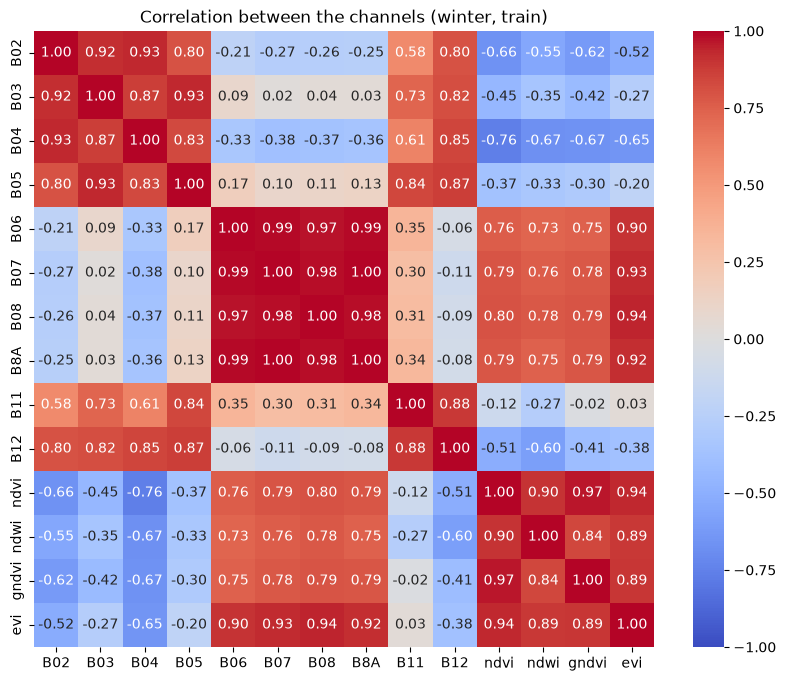

In [14]:
C, meta = data["winter"]
train = np.flatnonzero((meta["split"] == "train").to_numpy())
rows = C[np.random.default_rng(42).choice(train, 20_000, replace=False)].reshape(-1, C.shape[2])
rows = rows[np.isfinite(rows[:, 0])]

plt.figure(figsize=(10, 8))
sns.heatmap(pd.DataFrame(rows, columns=features.CHANNELS).corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between the channels (winter, train)")
plt.show()

The four indices are strongly related (0.84 to 0.97). Among the bands, three groups behave alike:

| Group | Bands | Correlation |
|---|---|---|
| visible and the first red-edge band | B02, B03, B04, B05 | 0.80 to 0.93 |
| red-edge and near-infrared | B06, B07, B08, B8A | 0.97 to 0.995 |
| short-wave infrared | B11, B12 | 0.88 |

B07 and B8A (0.995) are as close as EVI and SAVI were. They are still kept: SAVI was computed from bands that are already in the input, so it added nothing new, while B07 and B8A are separate measurements at different wavelengths. Tree models are not harmed by correlated inputs. The feature importance of LightGBM in the next notebook will show whether some channels can be dropped.

## Feature Table
The same data is given to the models in two shapes:

| Shape | Size | Models |
|---|---|---|
| sequence | samples × dekads × 14 channels | LSTM, MiniRocket |
| table | samples × (dekads × 14) columns | Random Forest, LightGBM |

In the table, every column is one channel in one dekad, named like `ndvi_d05` (NDVI in dekad 5).

In [15]:
for season, (C, meta) in data.items():
    print(f"{season}: table {features.flatten(C).shape}")

C, meta = data["winter"]
pd.DataFrame(features.flatten(C[:5]), columns=features.feature_names(C.shape[1])).iloc[:, 10:24].round(3)

winter: table (459501, 336)
summer: table (519159, 252)


,ndvi_d01,ndwi_d01,gndvi_d01,evi_d01,B02_d02,B03_d02,B04_d02,B05_d02,B06_d02,B07_d02,B08_d02,B8A_d02,B11_d02,B12_d02
0,0.461,0.060,0.515,0.309,0.105,0.149,0.204,0.269,0.304,0.330,0.324,0.369,0.418,0.319
1,0.628,0.268,0.509,0.490,0.061,0.092,0.066,0.122,0.265,0.310,0.370,0.307,0.187,0.126
2,0.796,0.308,0.659,0.690,0.057,0.093,0.055,0.138,0.389,0.450,0.465,0.454,0.214,0.131
3,0.497,0.070,0.531,0.306,0.098,0.143,0.202,0.239,0.259,0.277,0.299,0.311,0.368,0.270
4,0.636,0.105,0.656,0.325,0.034,0.058,0.065,0.110,0.163,0.200,0.203,0.209,0.174,0.123


Winter has 336 columns (24 dekads × 14 channels) and summer 252 (18 × 14). The table is only a different view of the same array, so it takes no extra memory.

## Early Season Input
To answer *how early can the crop be recognised*, a model is given only the first k dekads. `features.truncate` hides the later dekads. LightGBM reads the hidden dekads as missing, and the other models fill the cut series. The chart shows one wheat sample cut after dekad 9 (31 December).

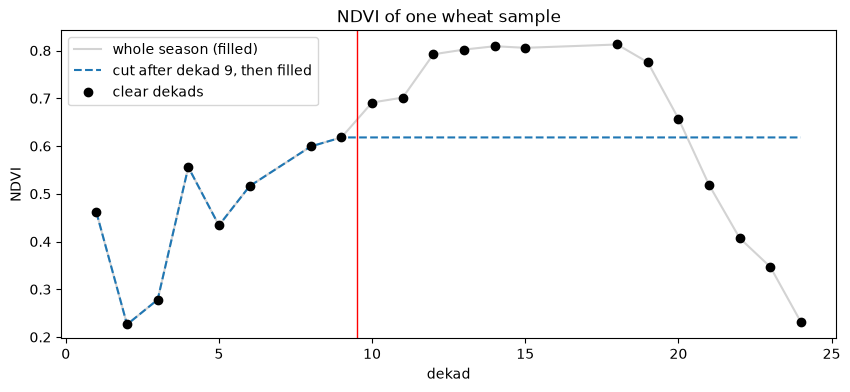

In [16]:
C, meta = data["winter"]
i = meta.index[(meta["crop"] == "wheat") & (meta["region"] == "ZAN")][0]
ndvi = features.CHANNELS.index("ndvi")
k = 9
seen = features.truncate(C[[i]], k)
dekads = np.arange(1, C.shape[1] + 1)

plt.figure(figsize=(10, 4))
plt.plot(dekads, features.fill(C[[i]])[0, :, ndvi], color="lightgray", label="whole season (filled)")
plt.plot(dekads, features.fill(seen)[0, :, ndvi], "--", label=f"cut after dekad {k}, then filled")
plt.plot(dekads, C[i, :, ndvi], "o", color="black", label="clear dekads")
plt.axvline(k + 0.5, color="red", lw=1)
plt.title("NDVI of one wheat sample")
plt.xlabel("dekad")
plt.ylabel("NDVI")
plt.legend()
plt.show()

Up to the cut the two lines are the same. After it, the cut series keeps the last clear value (about 0.62) and knows nothing about the rise to 0.81 and the harvest that came later. This is all a model would know about this field at the end of December.

## Phenology Features
Phenology is the timing of a crop's stages: sowing, growth, peak and harvest. Six numbers summarise the NDVI curve and six the NDWI curve of each sample:

| Feature | Meaning |
|---|---|
| `max` | highest value: how dense the crop gets |
| `peak_dekad` | dekad of the highest value: when it peaks |
| `min` | lowest value: bare soil or water |
| `mean` | average level over the season |
| `std` | how much the curve moves |
| `max_rise` | largest increase from one clear dekad to the next: fast growth |

They are computed only from the dekads seen, with nothing filled, so they also work on a cut series. They are candidates: they are kept only if they raise the validation macro-F1 of LightGBM in the next notebook.

In [17]:
pheno = {season: pd.DataFrame(features.phenology(C), columns=features.PHENOLOGY_NAMES) for season, (C, meta) in data.items()}

means = {}
for season, (C, meta) in data.items():
    train = (meta["split"] == "train").to_numpy()
    means[season] = pheno[season][train].groupby(meta.loc[train, "crop"].to_numpy()).mean()

pd.concat(means).round(2)

ndvi_max  ndvi_peak_dekad  ndvi_min  ndvi_mean  ndvi_std  \
winter beans           0.88            14.33      0.13       0.45      0.26   
       built_up        0.20            10.83      0.05       0.12      0.04   
       clover          0.91            13.41      0.23       0.70      0.22   
       flax            0.92            11.60      0.11       0.50      0.31   
       orchards        0.74            12.92      0.51       0.64      0.06   
       sugarbeet       0.91            12.22      0.14       0.57      0.29   
       vegetables      0.66            14.84      0.14       0.36      0.16   
       water           0.31            11.32     -0.15       0.11      0.12   
       wheat           0.91            13.80      0.15       0.51      0.27   
summer bare_soil       0.44            12.00      0.17       0.29      0.08   
       built_up        0.15            10.06      0.06       0.10      0.03   
       cotton          0.85            10.67      0.15       0.54      0.26   
       maize           0.81            10.15      0.18       0.48      0.22   
       orchards        0.73            12.64      0.47       0.59      0.07   
       rice            0.87             9.67      0.14       0.51      0.27   
       roads           0.21            11.56      0.05       0.12      0.04   
       vegetables      0.86             9.58      0.14       0.48      0.27   
       water           0.36            10.13     -0.44      -0.00      0.22   

                   ndvi_max_rise  ndwi_max  ndwi_peak_dekad  ndwi_min  \
winter beans                0.26      0.53        14.630000     -0.21   
       built_up             0.09      0.02        12.710000     -0.18   
       clover               0.29      0.46        11.760000     -0.07   
       flax                 0.36      0.55        13.240000     -0.13   
       orchards             0.10      0.29        16.190001      0.11   
       sugarbeet            0.27      0.60        11.820000     -0.11   
       vegetables           0.18      0.40        16.059999     -0.14   
       water                0.26      0.28        10.760000     -0.27   
       wheat                0.30      0.51        14.410000     -0.13   
summer bare_soil            0.12      0.14         8.730000     -0.10   
       built_up             0.05     -0.03         8.510000     -0.15   
       cotton               0.24      0.42        10.470000     -0.09   
       maize                0.30      0.35        10.210000     -0.11   
       orchards             0.15      0.25         7.820000      0.10   
       rice                 0.29      0.44        10.010000     -0.14   
       roads                0.09     -0.01        10.270000     -0.17   
       vegetables           0.29      0.45         9.770000     -0.10   
       water                0.45      0.16         9.750000     -0.56   

                   ndwi_mean  ndwi_std  ndwi_max_rise  
winter beans            0.12      0.24           0.26  
       built_up        -0.08      0.05           0.12  
       clover           0.27      0.16           0.23  
       flax             0.21      0.24           0.30  
       orchards         0.20      0.05           0.10  
       sugarbeet        0.29      0.25           0.28  
       vegetables       0.10      0.16           0.17  
       water            0.04      0.15           0.31  
       wheat            0.18      0.21           0.25  
summer bare_soil        0.02      0.07           0.11  
       built_up        -0.09      0.03           0.06  
       cotton           0.18      0.17           0.16  
       maize            0.11      0.14           0.19  
       orchards         0.17      0.04           0.08  
       rice             0.19      0.20           0.24  
       roads           -0.09      0.04           0.08  
       vegetables       0.17      0.19           0.19  
       water           -0.13      0.21           0.44

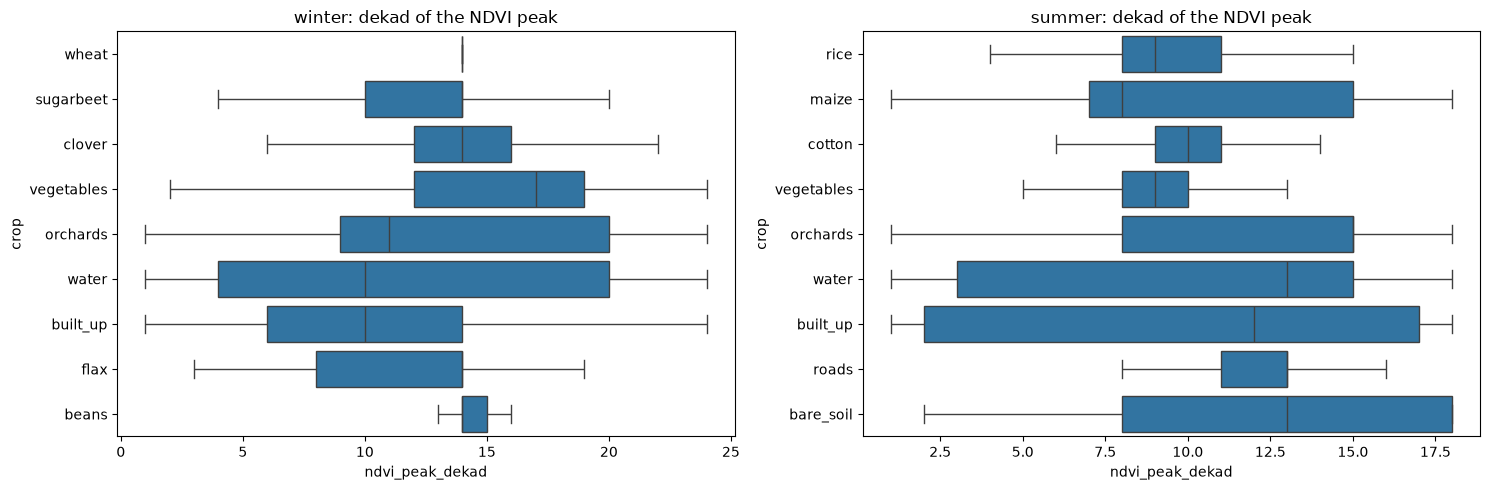

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (season, (C, meta)) in zip(axes, data.items()):
    train = (meta["split"] == "train").to_numpy()
    table = pheno[season][train].assign(crop=meta.loc[train, "crop"].to_numpy())
    sns.boxplot(data=table, x="ndvi_peak_dekad", y="crop", ax=ax, showfliers=False)
    ax.set_title(f"{season}: dekad of the NDVI peak")
plt.tight_layout()
plt.show()

The non-crop classes stand apart clearly:
- built-up and roads have a low NDVI maximum (0.15 to 0.21);
- water has a negative minimum;
- orchards have a high minimum (about 0.5) and a small std (0.06 to 0.07), because trees stay green.

The main crops are closer to each other. Their NDVI maximum is about the same (0.81 to 0.92, winter vegetables 0.66), and their mean peak differs by one to three dekads.

The peak dekad also follows the clouds. In Sidi Ghazi winter, 72% of the wheat samples peak in dekad 14, the only mostly clear dekad between 12 and 16, against 43% in Zankalon. A feature that partly reflects the cloud pattern of one district may help inside that district and hurt in the other. These features are therefore kept only if they raise the validation macro-F1 without lowering the cross-region score.

## Feature Scaling
LSTM and MiniRocket are sensitive to the scale of their inputs, and the channels have different ranges: reflectance is from 0 to about 0.7, the indices from -1 to 1. Each channel is standardised, `(x - mean) / std`, with the mean and standard deviation of the **training** samples only; missing values are ignored. Validation and test are scaled with the same numbers, so they never influence the training.

The tree models (Random Forest, LightGBM) split on thresholds and do not need scaling. The numbers are saved here and applied in the LSTM and MiniRocket notebooks with `features.standardize`.

In [19]:
scaling = {}
for season, (C, meta) in data.items():
    train = (meta["split"] == "train").to_numpy()
    scaling[season] = pd.DataFrame({
        "mean": [np.nanmean(C[train, :, c]) for c in range(C.shape[2])],
        "std": [np.nanstd(C[train, :, c]) for c in range(C.shape[2])],
    }, index=features.CHANNELS)

pd.concat(scaling, axis=1).round(3)

winter        summer       
        mean    std   mean    std
B02    0.050  0.027  0.055  0.029
B03    0.079  0.029  0.085  0.031
B04    0.074  0.049  0.085  0.050
B05    0.123  0.041  0.132  0.044
B06    0.250  0.109  0.234  0.089
B07    0.288  0.133  0.272  0.113
B08    0.299  0.142  0.279  0.120
B8A    0.301  0.133  0.286  0.116
B11    0.181  0.060  0.193  0.060
B12    0.120  0.053  0.131  0.055
ndvi   0.546  0.284  0.484  0.283
ndwi   0.202  0.219  0.149  0.202
gndvi  0.529  0.203  0.485  0.217
evi    0.402  0.280  0.346  0.245

The channels have very different spreads (std 0.03 for B02, 0.28 for NDVI), which confirms that standardising is needed for LSTM and MiniRocket. Each season gets its own numbers.

No log, Box-Cox or Yeo-Johnson transformation is applied: the tree models do not depend on the shape of a distribution, standardising is enough for the other two, and the indices are already bounded between -1 and 1.

---
# 3. Save the Outputs
Two small files are saved in `data/`. The feature arrays themselves are not saved: `features.py` builds them from the dataset in a few seconds, so there is no second copy that could go out of date.

| File | Content |
|---|---|
| `meta.parquet` | one row per clean sample: id, district, season, crop, class number, split, fold, block |
| `prep.json` | per season: classes, channels, feature names, phenology names, class weights, scaling |

In [20]:
features.DATA.mkdir(exist_ok=True)
pd.concat([meta for _, meta in data.values()], ignore_index=True).to_parquet(features.DATA / "meta.parquet", index=False)

prep = {}
for season, (C, meta) in data.items():
    prep[season] = {
        "classes": classes[season],
        "dekads": C.shape[1],
        "channels": features.CHANNELS,
        "features": features.feature_names(C.shape[1]),
        "phenology": features.PHENOLOGY_NAMES,
        "class_weights": weights[season].round(4).tolist(),
        "mean": scaling[season]["mean"].round(6).tolist(),
        "std": scaling[season]["std"].round(6).tolist(),
    }
(features.DATA / "prep.json").write_text(json.dumps(prep, indent=2))

print("Saved:", sorted(p.name for p in features.DATA.iterdir()))

Saved: ['meta.parquet', 'prep.json']


---
# 4. Summary

| Step | Result | Decision |
|---|---|---|
| Splits | 0 blocks and 0 pixels in two splits | used as they are |
| Missing dekads | winter 21.7%, summer 8.7%; no sample fully missing | kept as missing in storage |
| Filling | whole-season interpolation would use later dekads for 18% to 25% of the gaps | cut first, then fill; LightGBM gets the gaps |
| Outliers (bands) | 50 values above 1, out of 170 million | ignored |
| Target | 9 classes per season | fixed class numbers saved |
| Imbalance | weights from 0.33 to 28.7 | class weights, no sample dropped or repeated |
| Channels | 10 bands and NDVI, NDWI, GNDVI, EVI | 14 channels, SAVI left out |
| Feature table | 336 columns in winter, 252 in summer | sequence or table, depending on the model |
| Phenology | 12 features; non-crops separate well, crops less; the peak follows the clouds | candidates, tested in the next notebook |
| Scaling | train mean and std per channel | LSTM and MiniRocket only |

The outputs `meta.parquet` and `prep.json` are saved in `data/`, and `features.py` builds the same features for every model. The next notebook trains the classic models: the nearest class-mean floor, Random Forest and LightGBM.